# 02 · Observed fire weather: ERA5-Land FWI for India via Google Earth Engine
* Pulls **ERA5-Land daily aggregates (1950 → latest)** for all of India from GEE (`ee.data.computePixels`, no Drive exports needed).
* Computes the Canadian **FWI with exactly the same code and options as the CMIP6 dataset** (Quilcaille et al. 2023:
  `NSHeq` drying factor, continuous day length, DC overwintering) and the same "noon proxy":
  daily **max temperature**, daily **min RH** (from daily-mean dew point at Tmax), daily wind, 24-h precipitation.
* Two versions:
  **A** = FWI at 0.25° (fine, for maps and local records) and
  **B** = FWI from inputs averaged onto the model 2.5° cells (like a climate model sees the weather → used to evaluate models).
* Regions: **Central India** (Madhya Pradesh + Chhattisgarh) and **Uttarakhand** from FAO GAUL boundaries → GeoJSON for QGIS.
* Extras: the **noon-vs-proxy test** (quantifies the limitation) and a **MODIS burned-area check**.

Needs: notebook 01 finished (`data/grid_g025.json`), a GEE Cloud project. Runtime ≈ 30–60 min. Drive use ≈ 1.5–2 GB.

In [17]:
# ================= CONFIG =================
import os
BASE = os.environ.get('FWI_BASE', '/content/drive/MyDrive/FWI_India')
GEE_PROJECT = 'goggle-earth-499404'          # your Earth Engine Cloud project id
OUT = f'{BASE}/data/era5'
START = '1950-01-02'                          # first day of ERA5-Land daily aggregates (1950 = spin-up year)
END = None                                    # None → latest available day
RES = 0.25                                    # fine grid (deg)
DOMAIN_CENTRES = dict(lat=(6.0, 37.0), lon=(68.0, 98.0))   # 2.5° model cells whose centres fall here
REF_OBS = (1951, 1980)                        # reference period for obs fwixd / fwils thresholds
NOON_HOUR_UTC = 7                             # 07 UTC = 12:30 IST ≈ local solar noon at ~80°E
NOON_YEARS = (1990, 2025)                     # noon test period (first year = spin-up)
NTHREADS = 12
REGION_PATTERNS = {'Central India': [r'madhya', r'ch+at+is'], 'Uttarakhand': [r'uttar(akhand|anchal)']}

In [18]:
# [COLAB-ONLY]
from google.colab import drive
drive.mount('/content/drive')
import ee
try:
    ee.Initialize(project=GEE_PROJECT, opt_url='https://earthengine-highvolume.googleapis.com')
except Exception:
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT, opt_url='https://earthengine-highvolume.googleapis.com')
print('EE ok:', ee.String('hello').getInfo())
!git clone -q https://github.com/yquilcaille/FWI_CMIP6.git /content/FWI_CMIP6 2>/dev/null || echo 'repo already cloned'
!pip -q install rioxarray cftime netCDF4 geopandas

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EE ok: hello
repo already cloned


In [19]:
import sys, re, json, time, warnings, concurrent.futures as cf
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import shape, box
warnings.filterwarnings('ignore')
sys.path.insert(0, os.environ.get('FWI_CODE', '/content/FWI_CMIP6'))
import functions_calc_FWI as qf               # Quilcaille et al. FWI equations
os.makedirs(OUT, exist_ok=True); os.makedirs(f'{BASE}/maps', exist_ok=True); os.makedirs(f'{BASE}/figs', exist_ok=True)

## 1. Grids: model 2.5° cells (from notebook 01) and the aligned 0.25° ERA5 grid

In [20]:
g = json.load(open(f'{BASE}/data/grid_g025.json'))
clat, clon = np.array(g['lat']), np.array(g['lon'])
clat = clat[(clat >= DOMAIN_CENTRES['lat'][0]) & (clat <= DOMAIN_CENTRES['lat'][1])]
clon = clon[(clon >= DOMAIN_CENTRES['lon'][0]) & (clon <= DOMAIN_CENTRES['lon'][1])]
LAT_S, LAT_N = clat[0] - 1.25, clat[-1] + 1.25
LON_W, LON_E = clon[0] - 1.25, clon[-1] + 1.25
NY, NX = int(round((LAT_N - LAT_S) / RES)), int(round((LON_E - LON_W) / RES))
flat = LAT_S + RES / 2 + RES * np.arange(NY)          # ascending (south → north)
flon = LON_W + RES / 2 + RES * np.arange(NX)
BLK = int(round(2.5 / RES))                          # 10 × 10 fine pixels per model cell
print(f'domain {LAT_S}–{LAT_N}N, {LON_W}–{LON_E}E | fine {NY}×{NX} | coarse {clat.size}×{clon.size}')
GRID = {'dimensions': {'width': NX, 'height': NY},
        'affineTransform': {'scaleX': RES, 'shearX': 0, 'translateX': float(LON_W),
                            'shearY': 0, 'scaleY': -RES, 'translateY': float(LAT_N)},
        'crsCode': 'EPSG:4326'}

def block_mean(a, min_frac=0.25):
    """(…, NY, NX) → (…, NY/BLK, NX/BLK), NaN-aware; cell NaN if land fraction < min_frac."""
    s = a.shape[:-2] + (a.shape[-2] // BLK, BLK, a.shape[-1] // BLK, BLK)
    r = a.reshape(s)
    valid = np.isfinite(r).mean(axis=(-3, -1))
    with np.errstate(invalid='ignore'):
        m = np.nanmean(r, axis=(-3, -1))
    m[valid < min_frac] = np.nan
    return m.astype('float32')

domain 5.0–37.5N, 67.5–97.5E | fine 130×120 | coarse 13×12


## 2. Regions (FAO GAUL 2015 level-1) → GeoJSON + area weights on both grids

Central India ← ['Chhattisgarh', 'Madhya Pradesh']
Uttarakhand ← ['Uttarakhand']


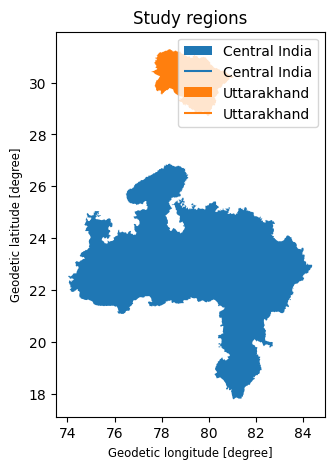

In [21]:
# [COLAB-ONLY]
gaul = ee.FeatureCollection('FAO/GAUL/2015/level1').filter(ee.Filter.eq('ADM0_NAME', 'India'))
all_names = gaul.aggregate_array('ADM1_NAME').distinct().getInfo()
REGION_EE, feats = {}, []
for reg, pats in REGION_PATTERNS.items():
    names = [n for n in all_names if any(re.search(p, n.lower()) for p in pats)]
    print(reg, '←', names)
    assert names, f'no GAUL match for {reg}; available: {sorted(all_names)}'
    geom = gaul.filter(ee.Filter.inList('ADM1_NAME', names)).geometry().simplify(maxError=1000)
    REGION_EE[reg] = geom
    feats.append({'region': reg, 'states': ', '.join(names), 'geometry': shape(geom.getInfo())})
regions = gpd.GeoDataFrame(feats, crs='EPSG:4326')
regions.to_file(f'{BASE}/maps/regions.geojson', driver='GeoJSON')
regions.plot(column='region', legend=True, figsize=(5, 5)); plt.title('Study regions'); plt.show()

In [22]:
regions = gpd.read_file(f'{BASE}/maps/regions.geojson')

def overlap_weights(poly, lats, lons, d):
    """Area weight of each cell inside poly (overlap fraction × cos(lat))."""
    w = np.zeros((lats.size, lons.size))
    minx, miny, maxx, maxy = poly.bounds
    for i, la in enumerate(lats):
        if la + d / 2 < miny or la - d / 2 > maxy:
            continue
        for j, lo in enumerate(lons):
            if lo + d / 2 < minx or lo - d / 2 > maxx:
                continue
            c = box(lo - d / 2, la - d / 2, lo + d / 2, la + d / 2)
            if poly.intersects(c):
                w[i, j] = poly.intersection(c).area / c.area * np.cos(np.deg2rad(la))
    return w

W_FINE = {r.region: overlap_weights(r.geometry, flat, flon, RES) for r in regions.itertuples()}
W_COARSE = {r.region: overlap_weights(r.geometry, clat, clon, 2.5) for r in regions.itertuples()}
wds = xr.Dataset({f'w_{k.replace(" ", "_")}': (('lat', 'lon'), v) for k, v in W_COARSE.items()},
                 coords=dict(lat=clat, lon=clon))
wds.to_netcdf(f'{BASE}/data/region_weights_g025.nc')
xr.Dataset({f'w_{k.replace(" ", "_")}': (('lat', 'lon'), v) for k, v in W_FINE.items()},
           coords=dict(lat=flat, lon=flon)).to_netcdf(f'{BASE}/data/region_weights_025.nc')
for k, v in W_COARSE.items():
    print(f'{k}: {(v > 0).sum()} model cells; weights (rows S→N):\n', np.round(v[v.any(1)][:, v.any(0)] / v.max(), 2))

def region_mean(a, w):
    """a (..., ny, nx) weighted mean ignoring NaNs."""
    m = np.isfinite(a)
    return np.nansum(np.where(m, a, 0) * w, axis=(-2, -1)) / np.maximum((m * w).sum(axis=(-2, -1)), 1e-12)

Central India: 15 model cells; weights (rows S→N):
 [[0.   0.   0.   0.49 0.01]
 [0.1  0.45 0.41 0.89 0.24]
 [0.12 0.84 0.96 1.   0.39]
 [0.   0.14 0.4  0.04 0.  ]]
Uttarakhand: 4 model cells; weights (rows S→N):
 [[0.67 0.16]
 [1.   0.19]]


## 3. ERA5-Land fetch from GEE (one request per month, parallel)

In [23]:
# [COLAB-ONLY]
DAILY = ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
BANDS = ['temperature_2m_max', 'dewpoint_temperature_2m', 'u_component_of_wind_10m',
         'v_component_of_wind_10m', 'total_precipitation_sum']
if END is None:
    END = ee.Date(DAILY.aggregate_max('system:time_start')).format('YYYY-MM-dd').getInfo()
print('ERA5-Land daily available until', END)

def _prep(im, bands):
    return im.select(bands).reduceResolution(ee.Reducer.mean(), maxPixels=256).unmask(-9999).toFloat()

def _compute(img, grid=None):
    for k in range(7):
        try:
            return ee.data.computePixels({'expression': img, 'fileFormat': 'NUMPY_NDARRAY', 'grid': grid or GRID})
        except Exception as e:
            if k == 6:
                raise
            time.sleep(3 * 2 ** k)

def fetch_month(ym):
    t0 = pd.Timestamp(ym); t1 = t0 + pd.offsets.MonthBegin(1)
    s, e = max(t0, pd.Timestamp(START)), min(t1, pd.Timestamp(END) + pd.Timedelta(days=1))
    base = DAILY.filterDate(s.strftime('%Y-%m-%d'), e.strftime('%Y-%m-%d'))
    ic = base.map(lambda im: _prep(im, BANDS))
    return _unpack(_compute(ic.toBands()), BANDS, _dates(base))

ERA5-Land daily available until 2026-10-13


## 4. FWI engine (Quilcaille et al. code, day by day, keeps its state across months)

In [24]:
def _unpack(arr, bands, dates=None):
    """computePixels structured array → dates, {band: (n, ny, nx) south-up}.
    Uses image order (toBands keeps collection order; bands repeat per image) when `dates` is given,
    otherwise parses '<system:index>_<band>' field names."""
    names = list(arr.dtype.names)
    nb = len(bands)
    if dates is not None and len(names) == len(dates) * nb:
        cols = {b: names[k::nb] for k, b in enumerate(bands)}
        assert all(c.split('_', 1)[1] == b for b in bands for c in cols[b]), names[:nb]
        dates = pd.DatetimeIndex(dates)
    else:
        by = {}
        for n in names:
            idx, b = n.split('_', 1)
            by.setdefault(idx[:8], {})[b] = n
        keys = sorted(d for d in by if all(b in by[d] for b in bands))
        cols = {b: [by[d][b] for d in keys] for b in bands}
        dates = pd.to_datetime(keys, format='%Y%m%d')
    out = {}
    for b in bands:
        st = np.stack([arr[c] for c in cols[b]]).astype('float32')[:, ::-1, :]   # north-up → south-up
        st[st <= -9000] = np.nan
        out[b] = st
    return dates, out

def _dates(ic):
    return pd.to_datetime(ic.aggregate_array('system:time_start').getInfo(), unit='ms').normalize()

def ordered_prefetch(fn, items, workers=NTHREADS, ahead=None):
    """Like ThreadPoolExecutor.map (results in order) but keeps at most `ahead` requests in flight (bounded memory)."""
    ahead = ahead or 2 * workers
    items = list(items)
    with cf.ThreadPoolExecutor(workers) as ex:
        futs = [ex.submit(fn, it) for it in items[:ahead]]
        nxt = len(futs)
        for i in range(len(items)):
            r = futs[i].result()
            futs[i] = None
            if nxt < len(items):
                futs.append(ex.submit(fn, items[nxt])); nxt += 1
            yield r

class Cfg:
    adjust_DryingFactor = 'NSHeq'; adjust_DayLength = 'continuous'; adjust_overwinterDC = 'wDC'

def es_hpa(t):  # Magnus saturation vapour pressure (°C → hPa)
    return 6.112 * np.exp(17.62 * t / (243.12 + t))

def derive(raw):
    """ERA5-Land daily aggregates → FWI inputs (°C, %, km/h, mm)."""
    T = raw['temperature_2m_max'] - 273.15
    Td = raw['dewpoint_temperature_2m'] - 273.15
    RH = np.clip(100 * es_hpa(Td) / es_hpa(T), 0, 100)
    W = np.hypot(raw['u_component_of_wind_10m'], raw['v_component_of_wind_10m']) * 3.6
    P = np.maximum(raw['total_precipitation_sum'] * 1000, 0)
    return dict(T=T.astype('float32'), RH=RH.astype('float32'), W=W.astype('float32'), P=P.astype('float32'))

class FWIEngine:
    KEEP = ['ffmcPREV', 'dmcPREV', 'dcPREV', 'SeasonActive', 'DCf', 'rw', 'CounterSeasonActive']
    def __init__(self, lat1d, nlon):
        lat2d = np.repeat(lat1d[:, None], nlon, axis=1).astype(float)
        shp = lat2d.shape
        self.s = dict(ffmcPREV=np.full(shp, 85.), dmcPREV=np.full(shp, 6.), dcPREV=np.full(shp, 15.),
                      SeasonActive=np.zeros(shp, bool), DCf=np.full(shp, np.nan), rw=np.zeros(shp),
                      CounterSeasonActive=np.zeros(shp))
        self.lat2d, self.cfg, self.tprev = lat2d, Cfg(), None

    def run(self, dates, d, T_next2=None, comps=False):
        """dates (n,), d: dict of (n, ny, nx) arrays. T_next2: Tmax of the following 2 days (for season test)."""
        T = d['T']; n = T.shape[0]
        before = self.tprev if self.tprev is not None else np.repeat(T[:1], 2, axis=0)
        after = T_next2 if T_next2 is not None and len(T_next2) >= 2 else np.repeat(T[-1:], 2, axis=0)
        Text = np.concatenate([before, T, after]).astype(float)
        fwi = np.empty(T.shape, 'float32')
        cc = {k: np.empty(T.shape, 'float32') for k in ['ffmc', 'dmc', 'dc', 'isi', 'bui']} if comps else None
        with np.errstate(all='ignore'), warnings.catch_warnings():
            warnings.simplefilter('ignore')
            for k in range(n):
                c = {kk: np.copy(v) for kk, v in self.s.items()}
                c.update(LAT=self.lat2d, MONTH=int(dates[k].month), NUMB_DAY=int(dates[k].dayofyear),
                         TEMP_wDC=Text[k:k + 5], TEMP=Text[k + 2].copy(), RH=d['RH'][k].astype(float),
                         WIND=d['W'][k].astype(float), RAIN=d['P'][k].astype(float))
                c = qf.calcFWI(c, self.cfg)
                for kk in self.KEEP:
                    self.s[kk] = c[kk]
                fwi[k] = c['fwi']
                if comps:
                    for kk in cc:
                        cc[kk][k] = c[kk]
        self.tprev = T[-2:].astype(float)
        return fwi, cc

## 5. Main loop: fetch → derive → FWI (A: 0.25°, B: 2.5°) → accumulate outputs
Monthly requests run in parallel threads; months are processed in order (each month waits for the first 2 days of the
next month, needed by the fire-season test). Progress prints once per year.

In [25]:
def run_era5(month_iter, n_days_hint=None):
    engA, engB = FWIEngine(flat, NX), FWIEngine(clat, clon.size)
    fwiA, fwiB, fwiAagg, inB, reg_rows, mon = [], [], [], {k: [] for k in 'T RH W P'.split()}, [], {}
    pending = None

    def process(item, nxt):
        dates, d = item
        dB = {k: block_mean(v) for k, v in d.items()}
        fA, cA = engA.run(dates, d, None if nxt is None else nxt['T'][:2], comps=True)
        fB, _ = engB.run(dates, dB, None if nxt is None else block_mean(nxt['T'][:2]))
        fwiA.append(fA); fwiB.append(fB); fwiAagg.append(block_mean(fA))
        for k in inB:
            inB[k].append(dB[k])
        # regional daily means (0.25° weights for A and inputs; 2.5° weights for B)
        for reg in W_FINE:
            row = {f'{v}': region_mean(d[v], W_FINE[reg]) for v in 'T RH W P'.split()}
            row.update({f'{v}': region_mean(cA[v], W_FINE[reg]) for v in cA})
            row['fwiA'] = region_mean(fA, W_FINE[reg]); row['fwiB'] = region_mean(fB, W_COARSE[reg])
            reg_rows.append(pd.DataFrame(row, index=pd.Index(dates, name='time')).assign(region=reg))
        # monthly means of fine inputs (for composites)
        key = dates[0].strftime('%Y-%m')
        mon[key] = {v: np.nanmean(d[v], axis=0) if v != 'P' else np.nansum(d[v], axis=0) for v in 'T RH W P'.split()}
        mon[key]['FWI'] = np.nanmean(fA, axis=0)
        if dates[0].month == 1:
            print(dates[0].year, end=' ', flush=True)

    for item in month_iter:
        cur = (item[0], derive(item[1]))
        if pending is not None:
            process(pending, cur[1])
        pending = cur
    process(pending, None)
    return fwiA, fwiB, fwiAagg, inB, reg_rows, mon

In [26]:
# [COLAB-ONLY]
DONE = all(os.path.exists(f'{OUT}/{f}') for f in ['era5_fwi_daily_025.nc', 'era5_daily_g025.nc', 'era5_region_daily.csv'])
if DONE:
    res = None; print('ERA5 FWI already computed → loading saved files (delete them to recompute)')
else:
    months = pd.date_range(pd.Timestamp(START).to_period('M').to_timestamp(), END, freq='MS')
    print(len(months), 'monthly requests …')
    t0 = time.time()
    res = run_era5(ordered_prefetch(fetch_month, months))
    print(f'\ndone in {(time.time()-t0)/60:.1f} min')

ERA5 FWI already computed → loading saved files (delete them to recompute)


In [27]:
def save_outputs(res):
    fwiA, fwiB, fwiAagg, inB, reg_rows, mon = res
    regd = pd.concat(reg_rows).reset_index()
    times = pd.DatetimeIndex(regd[regd.region == regd.region.iloc[0]].time.values)
    regd.to_csv(f'{OUT}/era5_region_daily.csv', index=False)
    enc = lambda ds: {v: {'zlib': True, 'complevel': 4} for v in ds.data_vars}
    A = xr.Dataset({'fwi': (('time', 'lat', 'lon'), np.concatenate(fwiA))},
                   coords=dict(time=times, lat=flat, lon=flon),
                   attrs=dict(title='ERA5-Land FWI (A, 0.25deg), Quilcaille et al. algorithm, Tmax/RHmin proxy'))
    A.to_netcdf(f'{OUT}/era5_fwi_daily_025.nc', encoding=enc(A))
    B = xr.Dataset({'fwiB': (('time', 'lat', 'lon'), np.concatenate(fwiB)),
                    'fwiA_agg': (('time', 'lat', 'lon'), np.concatenate(fwiAagg)),
                    **{k: (('time', 'lat', 'lon'), np.concatenate(v)) for k, v in inB.items()}},
                   coords=dict(time=times, lat=clat, lon=clon),
                   attrs=dict(note='fwiB: FWI of 2.5deg-mean inputs (model-like); fwiA_agg: 2.5deg mean of 0.25deg FWI'))
    B.to_netcdf(f'{OUT}/era5_daily_g025.nc', encoding=enc(B))
    keys = sorted(mon)
    M = xr.Dataset({v: (('month', 'lat', 'lon'), np.stack([mon[k][v] for k in keys]).astype('float32'))
                    for v in ['T', 'RH', 'W', 'P', 'FWI']},
                   coords=dict(month=pd.to_datetime(keys), lat=flat, lon=flon),
                   attrs=dict(note='monthly mean Tmax (C), RHmin (%), wind (km/h), FWI; P = monthly total (mm)'))
    M.to_netcdf(f'{OUT}/era5_monthly_025.nc', encoding=enc(M))
    return A, B, regd

if res is not None:
    A, B, regd = save_outputs(res)
    del res
else:
    A, B = xr.open_dataset(f'{OUT}/era5_fwi_daily_025.nc'), xr.open_dataset(f'{OUT}/era5_daily_g025.nc')
    regd = pd.read_csv(f'{OUT}/era5_region_daily.csv', parse_dates=['time'])
print({f: f'{os.path.getsize(f"{OUT}/{f}")/1e6:.0f} MB' for f in os.listdir(OUT)})

{'era5_region_daily.csv': '13 MB', 'era5_fwi_daily_025.nc': '735 MB', 'era5_daily_g025.nc': '61 MB', 'era5_monthly_025.nc': '140 MB', 'era5_indicators_g025.nc': '0 MB', 'era5_indicators_025.nc': '9 MB', 'era5_region_annual.csv': '0 MB', 'era5_records.csv': '0 MB'}


## 6. Annual indicators (same definitions as the CMIP6 dataset)
`fwixx` annual max · `fwisa` annual peak of centred 90-day mean · `fwixd` days ≥ 95th pct of the reference period ·
`fwils` days with normalised FWI > 0.5. Obs thresholds use 1951–1980 (models use 1850–1899), so only fwixx/fwisa are
compared in absolute terms. Years: 1951 → last complete fire season (Feb–Jun) — the current year is kept for fwixx/fwisa
only if data reach 31 July.

In [28]:
def annual_indicators(fwi, ref=REF_OBS, which=('fwixx', 'fwisa', 'fwixd', 'fwils')):
    fwi = fwi.sel(time=slice('1951-01-01', None))
    out = xr.Dataset()
    if 'fwixx' in which:
        out['fwixx'] = fwi.groupby('time.year').max('time')
    if 'fwisa' in which:
        out['fwisa'] = fwi.fillna(0).rolling(time=90, center=True).mean().groupby('time.year').max('time').astype('float32')
    r = fwi.sel(time=slice(str(ref[0]), str(ref[1])))
    if 'fwixd' in which:
        thr = r.fillna(0).quantile(0.95, dim='time').drop_vars('quantile')
        out['fwixd'] = (fwi >= thr).groupby('time.year').sum('time').astype('float32')
    if 'fwils' in which:
        mn, mx = r.min('time'), r.max('time')
        out['fwils'] = (((fwi - mn) / (mx - mn)) > 0.5).groupby('time.year').sum('time').astype('float32')
    land = fwi.notnull().any('time')
    out = out.where(land)
    last = int(fwi.time.dt.year.max())
    last_day = pd.Timestamp(fwi.time.values[-1])
    if last_day < pd.Timestamp(f'{last}-12-31'):
        for k in ('fwixd', 'fwils'):
            if k in out:
                out[k] = out[k].where(out.year < last)
        if last_day < pd.Timestamp(f'{last}-07-31'):
            out = out.where(out.year < last)
    return out

indB = annual_indicators(B.fwiB)
indAagg = annual_indicators(B.fwiA_agg)
def chunked(fn, da, n=10, **kw):   # memory-friendly: process latitude bands separately
    return xr.concat([fn(da.isel(lat=slice(i, i + n)).load(), **kw) for i in range(0, da.lat.size, n)], 'lat')
indA = chunked(annual_indicators, A.fwi, which=('fwixx', 'fwisa'))
xr.Dataset({**{f'{k}_B': indB[k] for k in indB}, **{f'{k}_Aagg': indAagg[k] for k in indAagg}}).to_netcdf(f'{OUT}/era5_indicators_g025.nc')
indA.to_netcdf(f'{OUT}/era5_indicators_025.nc')

rows = []
for reg in W_COARSE:
    for k in ['fwixx', 'fwisa', 'fwixd', 'fwils']:
        rows.append(pd.Series(region_mean(indB[k].values, W_COARSE[reg]), index=indB.year.values, name=(reg, k, 'B')))
        rows.append(pd.Series(region_mean(indAagg[k].values, W_COARSE[reg]), index=indB.year.values, name=(reg, k, 'Aagg')))
    for k in ['fwixx', 'fwisa']:
        rows.append(pd.Series(region_mean(indA[k].values, W_FINE[reg]), index=indA.year.values, name=(reg, k, 'A025')))
regann = pd.concat(rows, axis=1); regann.columns.names = ['region', 'indicator', 'version']
regann.index.name = 'year'
regann.to_csv(f'{OUT}/era5_region_annual.csv')
regann.round(1).tail()

region    Central India                                                       \
indicator         fwixx       fwisa       fwixd      fwils       fwixx fwisa   
version               B  Aagg     B  Aagg     B Aagg     B  Aagg  A025  A025   
year                                                                           
2022               69.9  69.9  54.0  54.1   8.0  8.0  87.0  87.4  72.4  55.0   
2023               65.6  65.3  41.0  41.3   2.3  1.6  67.4  67.9  67.7  41.9   
2024               70.3  70.1  46.8  46.8   4.1  4.2  62.8  62.6  71.7  46.8   
2025               65.8  65.4  46.1  46.3   2.3  2.6  64.3  63.1  67.4  46.9   
2026               70.5  70.8  47.6  47.7   0.0  0.0   0.0   0.0  73.3  48.2   

region    Uttarakhand                                                        
indicator       fwixx       fwisa       fwixd       fwils       fwixx fwisa  
version             B  Aagg     B  Aagg     B  Aagg     B  Aagg  A025  A025  
year                                                                         
2022             30.6  38.5  14.5  22.5   8.3  16.1  16.0  40.3  33.3  15.6  
2023             28.6  33.4  11.1  16.8   7.1   1.9   7.4   6.9  25.6  12.8  
2024             38.4  43.9  19.6  26.7  34.0  19.0  39.9  43.7  35.7  18.4  
2025             28.0  34.6  12.3  20.2   5.4   0.6   8.7  24.1  27.2  14.6  
2026             27.4  33.7  11.2  18.0   0.0   0.0   0.0   0.0  27.7  13.0

## 7. Observed records (what the models have to beat)

       region indicator  record  record_year  second  second_year                   top5_years  mean_1991_2020
Central India     fwixx   84.01         2010   83.44         1966 2010, 1966, 2002, 1956, 1972           73.28
Central India     fwisa   62.07         1956   61.56         1955 1956, 1955, 1966, 1964, 2010           50.71
Central India     fwixd   36.41         1956   34.29         1955 1956, 1955, 1964, 1984, 1966           11.79
  Uttarakhand     fwixx   41.80         1966   41.55         1975 1966, 1975, 1965, 1989, 1984           32.91
  Uttarakhand     fwisa   24.38         1966   22.36         1964 1966, 1964, 1955, 1965, 1960           15.85
  Uttarakhand     fwixd   39.04         1966   36.62         1965 1966, 1965, 2024, 1978, 2020           17.96


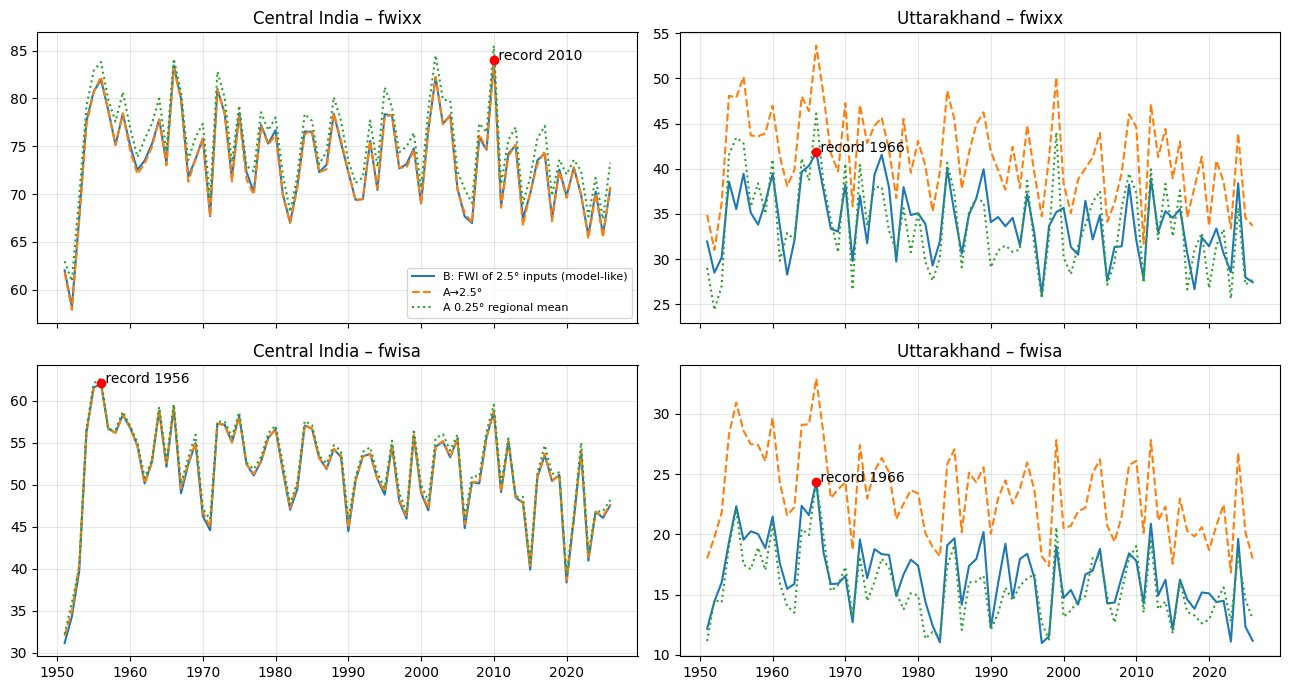

In [29]:
rec = []
for reg in W_COARSE:
    for k in ['fwixx', 'fwisa', 'fwixd']:
        s = regann[(reg, k, 'B')].dropna()
        top = s.sort_values(ascending=False).head(5)
        rec.append(dict(region=reg, indicator=k, record=round(top.iloc[0], 2), record_year=int(top.index[0]),
                        second=round(top.iloc[1], 2), second_year=int(top.index[1]),
                        top5_years=', '.join(map(str, top.index.astype(int))), mean_1991_2020=round(s.loc[1991:2020].mean(), 2)))
records = pd.DataFrame(rec)
records.to_csv(f'{OUT}/era5_records.csv', index=False)
print(records.to_string(index=False))

fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for i, reg in enumerate(W_COARSE):
    for j, k in enumerate(['fwixx', 'fwisa']):
        ax = axs[j, i]
        for v, st in [('B', '-'), ('Aagg', '--'), ('A025', ':')]:
            if (reg, k, v) in regann:
                ax.plot(regann.index, regann[(reg, k, v)], st, label={'B': 'B: FWI of 2.5° inputs (model-like)',
                        'Aagg': 'A→2.5°', 'A025': 'A 0.25° regional mean'}[v])
        s = regann[(reg, k, 'B')]
        ax.scatter(s.idxmax(), s.max(), color='r', zorder=5); ax.annotate(f' record {int(s.idxmax())}', (s.idxmax(), s.max()))
        ax.set_title(f'{reg} – {k}'); ax.grid(alpha=.3)
axs[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{BASE}/figs/02_era5_regional_series.png', dpi=150); plt.show()

## 8. Maps: climatological and record fwixx at 0.25° (+ GeoTIFFs for QGIS)

['MultiPolygon', 'MultiPolygon']


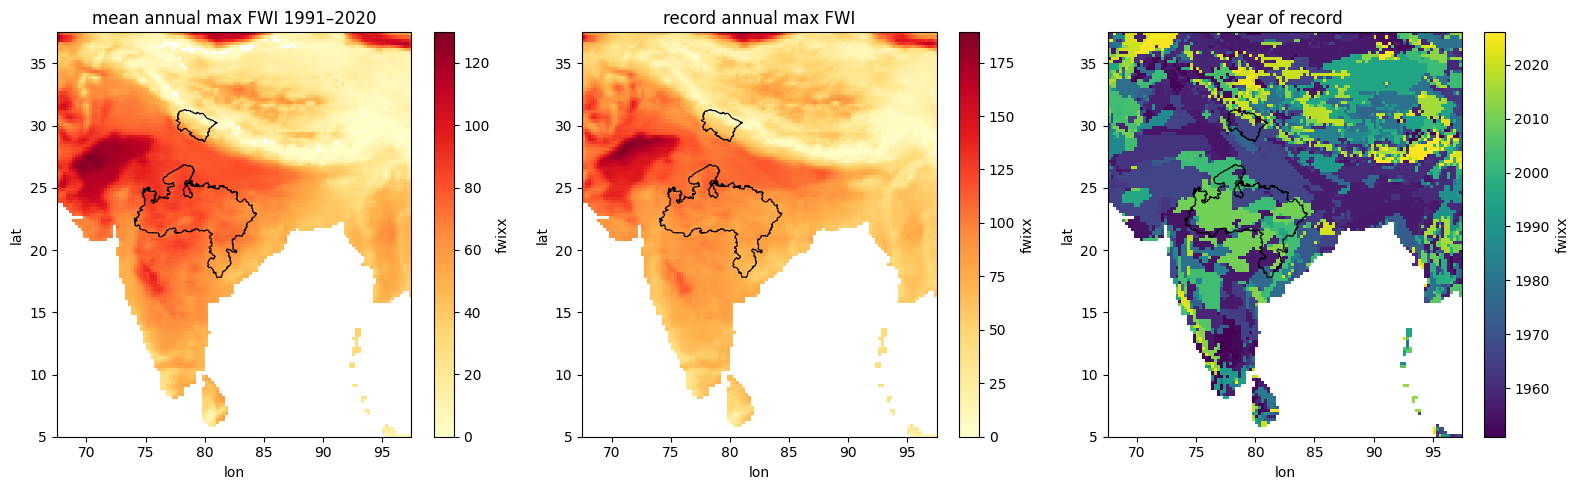

In [34]:
import rioxarray  # noqa
from shapely.geometry import MultiPolygon
from shapely.ops import unary_union

def polygons_only(g):
    """Earth Engine unions can come back as GeometryCollections (polygons + stray lines) → keep polygons only."""
    if g is None or g.is_empty or g.geom_type in ('Polygon', 'MultiPolygon'):
        return g
    u = unary_union([p for p in getattr(g, 'geoms', []) if p.geom_type in ('Polygon', 'MultiPolygon')])
    return u if u.geom_type == 'MultiPolygon' else MultiPolygon([u])

# clean the region outlines once and re-save them (notebooks 03/04 and QGIS read this file)
regions['geometry'] = regions.geometry.apply(polygons_only)
regions.to_file(f'{BASE}/maps/regions.geojson', driver='GeoJSON')
print(regions.geom_type.tolist())

def to_tif(da, path):
    da = da.rename(lat='y', lon='x').sortby('y', ascending=False)
    da.rio.write_crs('EPSG:4326', inplace=True).rio.to_raster(path)

clim = indA.fwixx.sel(year=slice(1991, 2020)).mean('year')
recmax = indA.fwixx.max('year'); recyr = indA.fwixx.fillna(-1).argmax('year') + int(indA.year[0])
to_tif(clim, f'{BASE}/maps/era5_fwixx_clim_1991_2020_025.tif')
to_tif(recmax, f'{BASE}/maps/era5_fwixx_record_025.tif')
to_tif(recyr.where(recmax.notnull()).astype('float32'), f'{BASE}/maps/era5_fwixx_record_year_025.tif')
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
clim.plot(ax=axs[0], cmap='YlOrRd', vmin=0); axs[0].set_title('mean annual max FWI 1991–2020')
recmax.plot(ax=axs[1], cmap='YlOrRd', vmin=0); axs[1].set_title('record annual max FWI')
recyr.where(recmax.notnull()).plot(ax=axs[2], cmap='viridis'); axs[2].set_title('year of record')
for ax in axs:
    regions.boundary.plot(ax=ax, color='k', lw=.8, aspect=None)
plt.tight_layout(); plt.savefig(f'{BASE}/figs/02_era5_maps.png', dpi=150); plt.show()

## 9. Limitation test: true local-noon FWI vs the daily Tmax/RHmin proxy
Same engine, same domain (region bounding box), but with ERA5-Land **hourly** 2 m temperature, dew point and wind at
07 UTC (≈ local noon). The first year is spin-up and is dropped.

In [32]:
u = regions.total_bounds                      # bounding box of both regions
iy0, iy1 = np.searchsorted(flat, u[1] - RES), np.searchsorted(flat, u[3] + RES)
ix0, ix1 = np.searchsorted(flon, u[0] - RES), np.searchsorted(flon, u[2] + RES)
SUB = dict(lat=flat[iy0:iy1], lon=flon[ix0:ix1])
GRID_SUB = {'dimensions': {'width': int(ix1 - ix0), 'height': int(iy1 - iy0)},
            'affineTransform': {'scaleX': RES, 'shearX': 0, 'translateX': float(flon[ix0] - RES / 2), 'shearY': 0,
                                'scaleY': -RES, 'translateY': float(flat[iy1 - 1] + RES / 2)}, 'crsCode': 'EPSG:4326'}
print('noon-test box:', SUB['lat'][0], SUB['lat'][-1], SUB['lon'][0], SUB['lon'][-1])

def run_noon(month_iter, lat1d, nlon):
    eng, out, pend = FWIEngine(lat1d, nlon), [], None
    for item in month_iter:
        if pend is not None:
            f, _ = eng.run(pend[0], pend[1], item[1]['T'][:2]); out.append((pend[0], f))
        pend = item
    f, _ = eng.run(pend[0], pend[1]); out.append((pend[0], f))
    t = pd.DatetimeIndex(np.concatenate([o[0] for o in out]))
    return xr.DataArray(np.concatenate([o[1] for o in out]), dims=('time', 'lat', 'lon'),
                        coords=dict(time=t, lat=lat1d, lon=SUB['lon']), name='fwi_noon')

noon-test box: 17.625 31.375 73.875 84.625


In [35]:
# [COLAB-ONLY]
HOURLY = ee.ImageCollection('ECMWF/ERA5_LAND/HOURLY')
HB = ['temperature_2m', 'dewpoint_temperature_2m', 'u_component_of_wind_10m', 'v_component_of_wind_10m']

def fetch_noon_month(ym):
    t0 = pd.Timestamp(ym); t1 = t0 + pd.offsets.MonthBegin(1)
    s, e = t0.strftime('%Y-%m-%d'), min(t1, pd.Timestamp(END) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    hb = HOURLY.filterDate(s, e).filter(ee.Filter.calendarRange(NOON_HOUR_UTC, NOON_HOUR_UTC, 'hour'))
    pb = DAILY.filterDate(s, e)
    h, p = hb.map(lambda im: _prep(im, HB)), pb.map(lambda im: _prep(im, ['total_precipitation_sum']))
    dh, xh = _unpack(_compute(h.toBands(), GRID_SUB), HB, _dates(hb))
    dp, xp = _unpack(_compute(p.toBands(), GRID_SUB), ['total_precipitation_sum'], _dates(pb))
    assert (dh[:min(len(dh), len(dp))] == dp[:min(len(dh), len(dp))]).all(), 'hourly/daily date mismatch'
    n = min(len(dh), len(dp))
    T = xh['temperature_2m'][:n] - 273.15; Td = xh['dewpoint_temperature_2m'][:n] - 273.15
    d = dict(T=T, RH=np.clip(100 * es_hpa(Td) / es_hpa(T), 0, 100),
             W=np.hypot(xh['u_component_of_wind_10m'][:n], xh['v_component_of_wind_10m'][:n]) * 3.6,
             P=np.maximum(xp['total_precipitation_sum'][:n] * 1000, 0))
    return dh[:n], {k: v.astype('float32') for k, v in d.items()}

In [36]:
# [COLAB-ONLY]
nm = pd.date_range(f'{NOON_YEARS[0]}-01-01', min(pd.Timestamp(f'{NOON_YEARS[1]}-12-01'), pd.Timestamp(END)), freq='MS')
noon = run_noon(ordered_prefetch(fetch_noon_month, nm), SUB['lat'], SUB['lon'].size)
noon.to_netcdf(f'{OUT}/era5_fwi_noon_sub_025.nc', encoding={'fwi_noon': {'zlib': True}})

In [37]:
def noon_vs_proxy(noon, A):
    noon = noon if noon is not None else xr.open_dataarray(f'{OUT}/era5_fwi_noon_sub_025.nc')
    prox = A.fwi.sel(lat=noon.lat, lon=noon.lon, time=noon.time)
    yrs = slice(str(NOON_YEARS[0] + 1), None)
    noon, prox = noon.sel(time=yrs), prox.sel(time=yrs)
    rows = []
    for reg in W_FINE:
        w = W_FINE[reg][np.isin(flat, noon.lat.values)][:, np.isin(flon, noon.lon.values)]
        sn = pd.Series(region_mean(noon.values, w), noon.time.values)
        sp = pd.Series(region_mean(prox.values, w), noon.time.values)
        fs = sn.index.month.isin([2, 3, 4, 5, 6])
        ann_n, ann_p = sn.groupby(sn.index.year).max(), sp.groupby(sp.index.year).max()
        rows.append(dict(region=reg, mean_FebJun_noon=sn[fs].mean(), mean_FebJun_proxy=sp[fs].mean(),
                         fwixx_noon=ann_n.mean(), fwixx_proxy=ann_p.mean(),
                         fwixx_ratio_proxy_to_noon=(ann_p / ann_n).mean(),
                         fwixx_rank_corr=ann_n.corr(ann_p, method='spearman'),
                         daily_corr_FebJun=sn[fs].corr(sp[fs])))
    return pd.DataFrame(rows).round(3)

nvp = noon_vs_proxy(noon, A)
nvp.to_csv(f'{OUT}/noon_vs_proxy.csv', index=False)
nvp

,region,mean_FebJun_noon,mean_FebJun_proxy,fwixx_noon,fwixx_proxy,fwixx_ratio_proxy_to_noon,fwixx_rank_corr,daily_corr_FebJun
0,Central India,42.929,40.786,77.711,70.071,0.902,0.920,0.992
1,Uttarakhand,12.948,11.525,37.211,31.967,0.863,0.959,0.995


**How to read it:** a ratio > 1 means the Tmax/RHmin proxy gives *higher* FWI than true noon values (expected — Tmax and
RHmin occur ~2–3 h after noon). High rank correlation means the *ranking of years* (what UNSEEN uses) is preserved, so the
limitation shifts the level but not which years are extreme. Quote these numbers in your limitations section.

## 10. Does high FWI mean big fire years? MODIS burned area (MCD64A1, Feb–Jun)

In [38]:
# [COLAB-ONLY]
mcd = ee.ImageCollection('MODIS/061/MCD64A1').select('BurnDate')
last_y = int(str(END)[:4]) - (0 if str(END)[5:7] >= '07' else 1)
def _ba(args):
    reg, y = args
    burned = mcd.filterDate(f'{y}-02-01', f'{y}-07-01').max().gt(0)
    km2 = ee.Image.pixelArea().divide(1e6).updateMask(burned).reduceRegion(
        ee.Reducer.sum(), REGION_EE[reg], scale=500, maxPixels=1e13, tileScale=4).get('area')
    return dict(region=reg, year=y, burned_km2=ee.Number(km2).getInfo())
ba = list(ordered_prefetch(_ba, [(r, y) for r in REGION_EE for y in range(2001, last_y + 1)], workers=8))
ba = pd.DataFrame(ba); ba.to_csv(f'{OUT}/modis_burned_area_FebJun.csv', index=False)

Central India  fwixx: Spearman r = -0.13
Central India  fwisa: Spearman r = 0.14
Central India  fwixd: Spearman r = -0.16
Uttarakhand    fwixx: Spearman r = 0.70
Uttarakhand    fwisa: Spearman r = 0.67
Uttarakhand    fwixd: Spearman r = 0.41


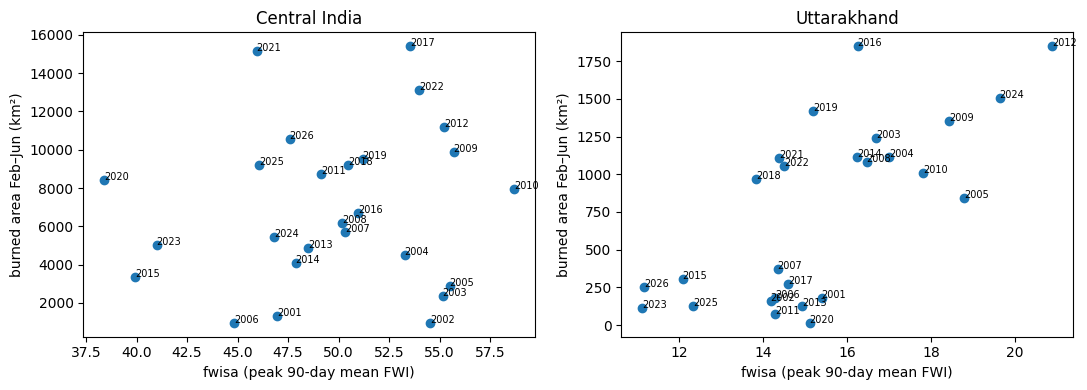

In [39]:
ba = pd.read_csv(f'{OUT}/modis_burned_area_FebJun.csv')
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, reg in zip(axs, W_COARSE):
    b = ba[ba.region == reg].set_index('year').burned_km2
    for k in ['fwixx', 'fwisa', 'fwixd']:
        s = regann[(reg, k, 'B')].reindex(b.index)
        print(f'{reg:14s} {k}: Spearman r = {s.corr(b, method="spearman"):.2f}')
    s = regann[(reg, 'fwisa', 'B')].reindex(b.index)
    ax.scatter(s, b); [ax.annotate(str(y), (s[y], b[y]), fontsize=7) for y in b.index]
    ax.set_xlabel('fwisa (peak 90-day mean FWI)'); ax.set_ylabel('burned area Feb–Jun (km²)'); ax.set_title(reg)
plt.tight_layout(); plt.savefig(f'{BASE}/figs/02_fwi_vs_burned_area.png', dpi=150); plt.show()